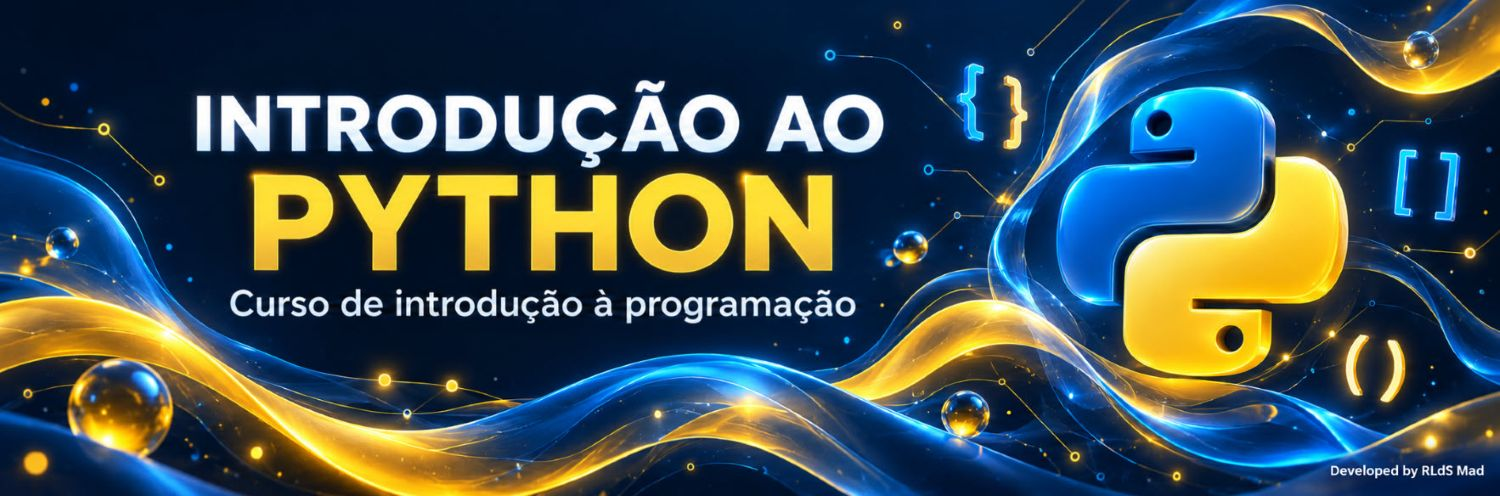

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_06_Visao_Computacional_CNN.ipynb)


# Nível IA · Módulo 6 – Visão computacional com redes convolucionais
## Ensinar uma rede a ver

No módulo anterior, a rede neuronal não ganhou à regressão logística numa tabela de clientes. Com **imagens**, a história é outra. Uma imagem é uma grelha de números em que a **posição** importa: um píxel tem significado em relação aos vizinhos, e o mesmo traço pode aparecer em qualquer sítio. As **redes convolucionais** (CNN, *convolutional neural networks*) foram desenhadas para aproveitar exatamente isso, e são a base da visão computacional moderna: reconhecimento de objetos, imagiologia médica, condução autónoma, controlo de qualidade industrial.

Neste módulo constróis a ideia peça a peça: primeiro a **convolução** e o ***pooling*** à mão, com NumPy, numa fotografia; depois uma CNN pequena em PyTorch que reconhece dígitos escritos à mão; e no fim vês o que a rede aprendeu e como a tornar mais robusta.

> **Objetivos:** representar imagens como tensores no formato (N, C, A, L); perceber e calcular uma convolução, o efeito do *padding* e do *stride*, e o *max pooling*; construir uma CNN com `nn.Conv2d`, `nn.MaxPool2d` e `nn.Linear`, e acompanhar as formas camada a camada; classificar várias classes com `nn.CrossEntropyLoss` e *softmax*; avaliar com a matriz de confusão e os exemplos mal classificados; visualizar os filtros e os mapas de ativação; comparar uma CNN com uma rede densa e usar *data augmentation* para ganhar robustez.

**Pré-requisitos:** módulos N3_04 (redes neuronais de raiz) e N3_05 (PyTorch). Os dados principais vêm com o scikit-learn e funcionam sem Internet; a secção 8, opcional, descarrega o conjunto Fashion-MNIST.

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e dispositivo |
| 1. Imagens como tensores | os dígitos 8×8 e o formato (N, C, A, L) |
| 2. A convolução | filtros, arestas, *padding* e *stride* |
| 3. *Pooling* | resumir e ganhar tolerância a pequenas deslocações |
| 4. Uma CNN para dígitos | arquitetura, formas e treino com várias classes |
| 5. Avaliar | matriz de confusão, erros e probabilidades |
| 6. O que a rede aprendeu | filtros e mapas de ativação |
| 7. Robustez e *data augmentation* | CNN contra rede densa em imagens deslocadas |
| 8. Opcional: Fashion-MNIST | imagens 28×28 de roupa, no Colab |
| 9. Experimenta | três exercícios com solução |


## 0. Preparação


In [1]:
# Executar esta célula

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_digits, load_sample_image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset

plt.rcParams.update({"figure.dpi": 100})
torch.manual_seed(0)
np.random.seed(0)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | dispositivo: {dispositivo}")

PyTorch 2.15.0+cu132 | dispositivo: cpu


## 1. Imagens como tensores

### 1.1 Os dígitos escritos à mão

O scikit-learn traz um conjunto com 1797 dígitos escritos à mão, digitalizados em imagens de **8 × 8 píxeis**, com intensidades de 0 (branco) a 16 (preto). É uma versão pequena do famoso MNIST (28 × 28), e por isso treina em segundos, sem GPU nem Internet.


Imagens: (1797, 8, 8) | rótulos: (1797,) | intensidades de 0.0 a 16.0
Exemplos por dígito: [178 182 177 183 181 182 181 179 174 180]


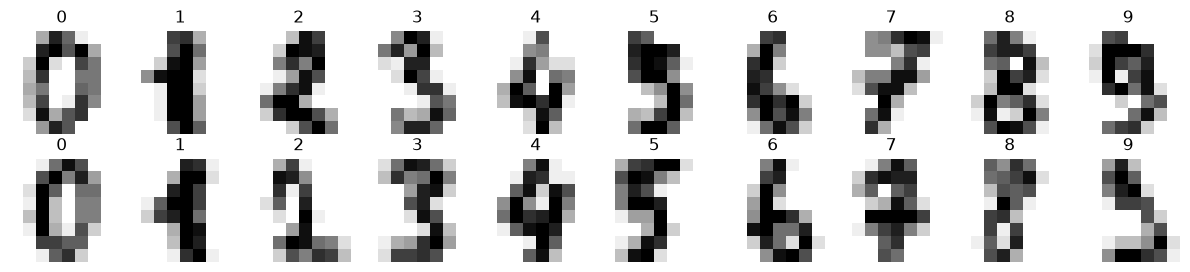

A primeira imagem, em números:
 [[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


In [2]:
# Executar esta célula

digitos = load_digits()
imagens, rotulos = digitos.images, digitos.target
print("Imagens:", imagens.shape, "| rótulos:", rotulos.shape, "| intensidades de", imagens.min(), "a", imagens.max())
print("Exemplos por dígito:", np.bincount(rotulos))

fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, i in zip(axs.ravel(), range(20)):
    ax.imshow(imagens[i], cmap="gray_r")
    ax.set_title(rotulos[i])
    ax.axis("off")
plt.tight_layout()
plt.show()
print("A primeira imagem, em números:\n", imagens[0].astype(int))

Para o computador, uma imagem é só esta **grelha de números**. Uma imagem a cores tem três grelhas, uma por **canal** (vermelho, verde e azul).

### 1.2 O formato (N, C, A, L)

As camadas convolucionais do PyTorch esperam um tensor com **quatro dimensões**: **N** imagens, cada uma com **C** canais, de **A**ltura × **L**argura. Os dígitos têm um só canal (tons de cinzento), por isso acrescentamos essa dimensão com `unsqueeze(1)`. Também dividimos por 16, para as intensidades ficarem entre 0 e 1 (é a normalização, N3_03 §3.4).

Separamos treino (60 %), validação (15 %) e teste (25 %), estratificando pelos dígitos.


In [3]:
# Executar esta célula

X = (imagens / 16).astype(np.float32)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, rotulos, test_size=0.25, stratify=rotulos, random_state=42)
X_treino, X_val, y_treino, y_val = train_test_split(X_treino, y_treino, test_size=0.2, stratify=y_treino, random_state=42)


def para_tensor(imgs: np.ndarray) -> torch.Tensor:
    """(N, A, L) em NumPy → (N, 1, A, L) em PyTorch."""
    return torch.tensor(imgs).unsqueeze(1)


print("Treino:", para_tensor(X_treino).shape, "| validação:", len(X_val), "| teste:", len(X_teste))

Treino: torch.Size([1077, 1, 8, 8]) | validação: 270 | teste: 450


## 2. A convolução

### 2.1 A ideia: um filtro que desliza

Uma **convolução** passa um pequeno quadrado de pesos, o **filtro** (ou *kernel*), por cima da imagem. Em cada posição, multiplica os pesos pelos píxeis que estão por baixo e soma tudo: o resultado é um píxel da imagem de saída, chamada **mapa de ativação** (*feature map*).

O filtro abaixo deteta **arestas verticais**: dá valores altos onde a imagem passa de escuro (à esquerda) para claro (à direita), e zero onde a imagem é uniforme.

$$\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$$

Este é o **filtro de Sobel**, usado em processamento de imagem muito antes das redes neuronais. A diferença das CNN é que **os pesos dos filtros são aprendidos**, em vez de escolhidos à mão.

Começamos por programar a convolução com dois ciclos, para se ver exatamente o que acontece:


In [4]:
# Executar esta célula

def convolucao(imagem: np.ndarray, filtro: np.ndarray) -> np.ndarray:
    """Convolução 2D sem padding e com stride 1 (como nas redes: sem inverter o filtro)."""
    k = filtro.shape[0]
    A, L = imagem.shape
    saida = np.zeros((A - k + 1, L - k + 1))
    for i in range(A - k + 1):
        for j in range(L - k + 1):
            saida[i, j] = np.sum(imagem[i:i + k, j:j + k] * filtro)
    return saida


sobel_vertical = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_horizontal = sobel_vertical.T

quadrado = np.zeros((6, 6))
quadrado[1:5, 1:5] = 1
print("Imagem: um quadrado claro\n", quadrado.astype(int))
print("Arestas verticais:\n", convolucao(quadrado, sobel_vertical).astype(int))

Imagem: um quadrado claro
 [[0 0 0 0 0 0]
 [0 1 1 1 1 0]
 [0 1 1 1 1 0]
 [0 1 1 1 1 0]
 [0 1 1 1 1 0]
 [0 0 0 0 0 0]]
Arestas verticais:
 [[ 3  0  0 -3]
 [ 4  0  0 -4]
 [ 4  0  0 -4]
 [ 3  0  0 -3]]


Os valores positivos marcam a aresta esquerda do quadrado (escuro → claro) e os negativos a direita (claro → escuro); no interior uniforme, o resultado é zero. A saída tem 4 × 4 píxeis, e não 6 × 6: o filtro 3 × 3 só cabe em 4 posições em cada direção.

### 2.2 Numa fotografia

Numa fotografia a sério (o scikit-learn traz uma, de um templo chinês), os filtros de Sobel revelam o contorno dos objetos. Primeiro convertemos a imagem para tons de cinzento, com a média dos três canais.


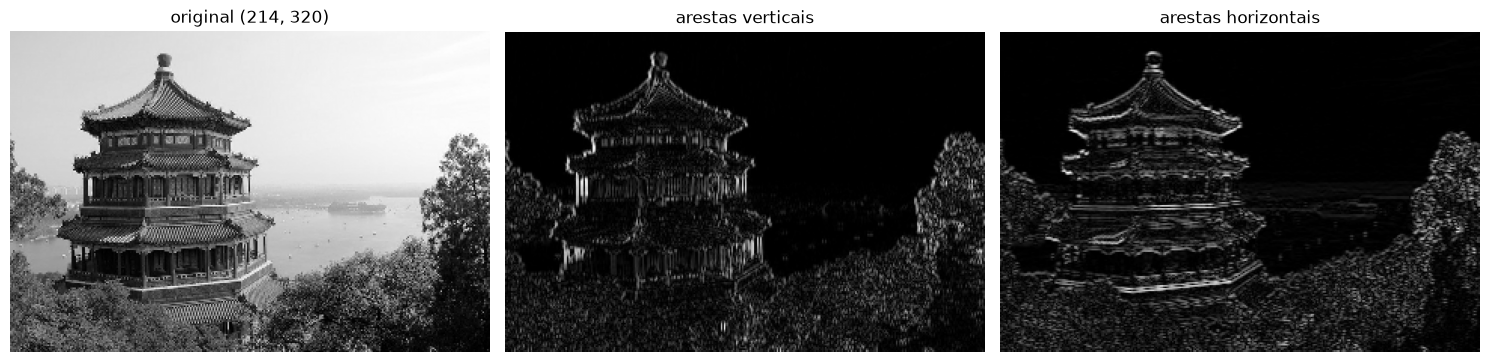

In [5]:
# Executar esta célula

foto = load_sample_image("china.jpg").mean(axis=2) / 255      # (427, 640), valores de 0 a 1
foto = foto[::2, ::2]                                          # metade do tamanho, para ser mais rápido

verticais = convolucao(foto, sobel_vertical)
horizontais = convolucao(foto, sobel_horizontal)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (imagem, titulo) in zip(axs, [(foto, f"original {foto.shape}"),
                                      (np.abs(verticais), "arestas verticais"),
                                      (np.abs(horizontais), "arestas horizontais")]):
    ax.imshow(imagem, cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.3 O mesmo com `nn.Conv2d`

No PyTorch, uma camada convolucional é `nn.Conv2d(canais_entrada, canais_saida, kernel_size)`. Se lhe dermos o filtro de Sobel como pesos, faz exatamente o mesmo cálculo, de forma vetorizada e muito mais rápida (e na GPU, se houver):


In [6]:
# Executar esta célula

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[:] = torch.tensor(sobel_vertical, dtype=torch.float32)

foto_t = torch.tensor(foto, dtype=torch.float32).reshape(1, 1, *foto.shape)    # (N, C, A, L)
with torch.no_grad():
    saida_torch = conv(foto_t)
print("Forma da saída:", tuple(saida_torch.shape))
print("Igual à nossa convolução?", np.allclose(saida_torch[0, 0].numpy(), verticais, atol=1e-5))

Forma da saída: (1, 1, 212, 318)
Igual à nossa convolução? True


### 2.4 *Padding*, *stride* e canais

Três parâmetros controlam a convolução:

| Parâmetro | O que faz | Exemplo |
| --- | --- | --- |
| `kernel_size` ($k$) | tamanho do filtro | 3 (o mais usado), 5, 7 |
| `padding` ($p$) | acrescenta $p$ píxeis de zeros à volta da imagem, para a saída não encolher | com $k = 3$, `padding=1` mantém o tamanho |
| `stride` ($s$) | o filtro avança $s$ píxeis de cada vez | `stride=2` reduz o tamanho para metade |

O tamanho da saída, em cada direção, é:

$$\text{saída} = \left\lfloor \frac{\text{entrada} + 2p - k}{s} \right\rfloor + 1$$

Uma camada tem normalmente **vários filtros** (`out_channels`), cada um à procura de um padrão diferente; cada filtro produz um mapa de ativação, e os mapas empilham-se como **canais** da saída. Se a entrada tiver vários canais (uma imagem a cores, ou a saída de outra convolução), cada filtro tem uma «fatia» de pesos por canal de entrada.


In [7]:
# Executar esta célula

entrada = torch.zeros(1, 1, 8, 8)                   # um dígito: 1 canal, 8 × 8
for k, p, s in [(3, 0, 1), (3, 1, 1), (3, 1, 2), (5, 2, 1)]:
    saida = nn.Conv2d(1, 16, kernel_size=k, padding=p, stride=s)(entrada)
    formula = (8 + 2 * p - k) // s + 1
    print(f"k={k}, padding={p}, stride={s}: saída {tuple(saida.shape)}  (fórmula: {formula} × {formula})")

camada = nn.Conv2d(1, 16, kernel_size=3)
print("\nPesos de Conv2d(1, 16, 3):", tuple(camada.weight.shape), "+", tuple(camada.bias.shape),
      "=", sum(p.numel() for p in camada.parameters()), "parâmetros")

k=3, padding=0, stride=1: saída (1, 16, 6, 6)  (fórmula: 6 × 6)
k=3, padding=1, stride=1: saída (1, 16, 8, 8)  (fórmula: 8 × 8)
k=3, padding=1, stride=2: saída (1, 16, 4, 4)  (fórmula: 4 × 4)
k=5, padding=2, stride=1: saída (1, 16, 8, 8)  (fórmula: 8 × 8)

Pesos de Conv2d(1, 16, 3): (16, 1, 3, 3) + (16,) = 160 parâmetros


Repara no número de parâmetros: 16 filtros de 3 × 3, mais 16 viéses, são **160 parâmetros**, e servem para uma imagem de qualquer tamanho. Uma camada densa (`nn.Linear`) que ligasse cada um dos 64 píxeis de um dígito a 16 neurónios precisaria de 1040; para a fotografia (213 × 320 píxeis), de mais de um milhão. É a primeira grande vantagem das convoluções: **partilhar os pesos** por todas as posições da imagem. A segunda é que um padrão aprendido num sítio (um traço, uma curva) é reconhecido **em qualquer sítio**.


## 3. *Pooling*

Depois de uma convolução, é habitual **reduzir** o mapa de ativação com ***max pooling***: divide-se o mapa em quadrados de 2 × 2 e fica-se só com o valor máximo de cada um. A imagem fica com metade da altura e da largura, o que tem duas vantagens:
- as camadas seguintes têm menos cálculos e menos parâmetros;
- a rede fica mais **tolerante a pequenas deslocações**: se um traço se mover um píxel dentro do quadrado, o máximo não muda.

Em NumPy, o *max pooling* 2 × 2 faz-se com um `reshape`:


Entrada:
 [[1 3 2 0]
 [4 2 1 1]
 [0 1 5 6]
 [2 2 7 3]] 
Max pooling 2 × 2:
 [[4 2]
 [2 7]]
nn.MaxPool2d dá o mesmo? True


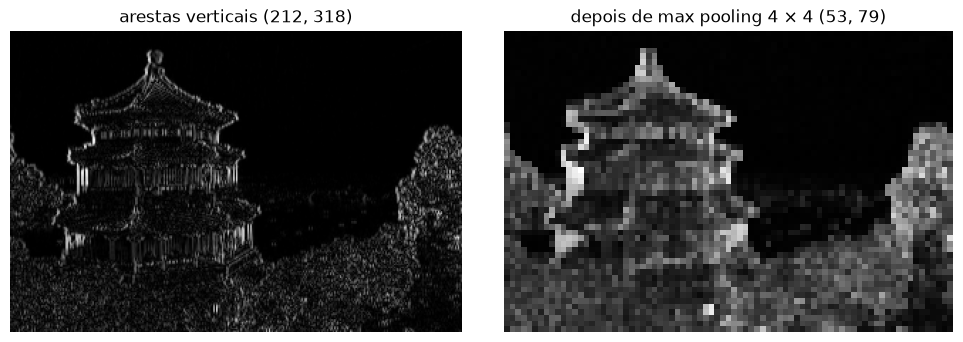

In [8]:
# Executar esta célula

def max_pooling(imagem: np.ndarray, t: int = 2) -> np.ndarray:
    A, L = (imagem.shape[0] // t) * t, (imagem.shape[1] // t) * t
    return imagem[:A, :L].reshape(A // t, t, L // t, t).max(axis=(1, 3))


exemplo = np.array([[1, 3, 2, 0],
                    [4, 2, 1, 1],
                    [0, 1, 5, 6],
                    [2, 2, 7, 3]])
print("Entrada:\n", exemplo, "\nMax pooling 2 × 2:\n", max_pooling(exemplo))
print("nn.MaxPool2d dá o mesmo?",
      np.array_equal(nn.MaxPool2d(2)(torch.tensor(exemplo, dtype=torch.float32)[None, None])[0, 0].numpy(), max_pooling(exemplo)))

reduzida = max_pooling(np.abs(verticais), 4)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].imshow(np.abs(verticais), cmap="gray")
axs[0].set_title(f"arestas verticais {verticais.shape}")
axs[1].imshow(reduzida, cmap="gray")
axs[1].set_title(f"depois de max pooling 4 × 4 {reduzida.shape}")
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

Com 16 vezes menos píxeis, os contornos principais continuam lá: o *pooling* guarda **onde, aproximadamente,** há uma aresta, e deita fora o pormenor exato.


## 4. Uma CNN para reconhecer dígitos

### 4.1 A arquitetura

Uma CNN típica tem duas partes:
1. um **extrator de atributos**: blocos de convolução → ReLU → *pooling*. Os primeiros blocos encontram padrões simples (traços, arestas); os seguintes combinam-nos em padrões mais complexos (curvas, laços);
2. um **classificador**: os mapas de ativação são «achatados» num vetor (`nn.Flatten`) e passam por camadas densas, até uma saída com **um valor por classe**.

A nossa rede, para imagens 8 × 8:


In [9]:
# Executar esta célula

class CNNDigitos(nn.Module):
    def __init__(self, filtros1: int = 16, filtros2: int = 32):
        super().__init__()
        self.extrator = nn.Sequential(
            nn.Conv2d(1, filtros1, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),          # 8×8 → 4×4
            nn.Conv2d(filtros1, filtros2, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 4×4 → 2×2
        )
        self.classificador = nn.Sequential(nn.Flatten(), nn.Linear(filtros2 * 2 * 2, 10))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classificador(self.extrator(x))


torch.manual_seed(0)
cnn = CNNDigitos()
x = torch.zeros(1, 1, 8, 8)
print(f"{'entrada':<30} {tuple(x.shape)}")
for camada in list(cnn.extrator) + list(cnn.classificador):
    x = camada(x)
    n_par = sum(p.numel() for p in camada.parameters())
    print(f"{str(camada):<30.30} {str(tuple(x.shape)):<16} {n_par:>5} parâmetros")
print("Total:", sum(p.numel() for p in cnn.parameters()), "parâmetros")

entrada                        (1, 1, 8, 8)
Conv2d(1, 16, kernel_size=(3,  (1, 16, 8, 8)      160 parâmetros
ReLU()                         (1, 16, 8, 8)        0 parâmetros
MaxPool2d(kernel_size=2, strid (1, 16, 4, 4)        0 parâmetros
Conv2d(16, 32, kernel_size=(3, (1, 32, 4, 4)     4640 parâmetros
ReLU()                         (1, 32, 4, 4)        0 parâmetros
MaxPool2d(kernel_size=2, strid (1, 32, 2, 2)        0 parâmetros
Flatten(start_dim=1, end_dim=- (1, 128)             0 parâmetros
Linear(in_features=128, out_fe (1, 10)           1290 parâmetros
Total: 6090 parâmetros


Acompanhar as formas camada a camada, como acima, é o melhor hábito para evitar erros: o número de entradas do `nn.Linear` (32 × 2 × 2 = 128) tem de bater certo com o que sai do extrator.

### 4.2 Várias classes: *softmax* e `CrossEntropyLoss`

Até agora as redes tinham uma saída (duas classes). Para **10 classes**, a rede devolve **10 *logits***, um por dígito. A função ***softmax*** transforma-os em probabilidades que somam 1:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

e a previsão é a classe com maior probabilidade (`argmax`). Como no N3_05, a função de perda recebe os *logits* e aplica a *softmax* internamente: é a `nn.CrossEntropyLoss`. Os rótulos são os **números das classes** (0 a 9), em inteiros (`torch.long`), e não vetores.


In [10]:
# Executar esta célula

logits = torch.tensor([[2.0, 0.5, -1.0, 0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 3.0]])     # 10 logits de um exemplo
probabilidades = torch.softmax(logits, dim=1)
print("probabilidades:", probabilidades.numpy().round(3), "| soma:", probabilidades.sum().item())
print("classe prevista:", probabilidades.argmax(dim=1).item())
print("perda se a resposta for 9:", nn.CrossEntropyLoss()(logits, torch.tensor([9])).item().__round__(3))
print("perda se a resposta for 2:", nn.CrossEntropyLoss()(logits, torch.tensor([2])).item().__round__(3))

probabilidades: [[0.208 0.046 0.01  0.031 0.028 0.028 0.028 0.028 0.028 0.564]] | soma: 0.9999999403953552
classe prevista: 9
perda se a resposta for 9: 0.572
perda se a resposta for 2: 4.572


### 4.3 Dados, *DataLoader* e treino

O `Dataset` devolve cada imagem com a forma (1, 8, 8) e o rótulo como inteiro. Tem uma opção `aumentar`, que só vamos usar na secção 7. As funções de treino e avaliação são as do N3_05, com uma diferença: a classe prevista é o `argmax` dos *logits*.


In [11]:
# Executar esta célula

def deslocar(imgs: np.ndarray, dx: int, dy: int) -> np.ndarray:
    """Desloca imagens (N, A, L) dx píxeis para a direita e dy para baixo, preenchendo com zeros."""
    saida = np.zeros_like(imgs)
    A, L = imgs.shape[1:]
    saida[:, max(dy, 0):A + min(dy, 0), max(dx, 0):L + min(dx, 0)] = \
        imgs[:, max(-dy, 0):A + min(-dy, 0), max(-dx, 0):L + min(-dx, 0)]
    return saida


class Digitos(Dataset):
    def __init__(self, imgs: np.ndarray, rotulos: np.ndarray, aumentar: bool = False):
        self.imgs, self.rotulos, self.aumentar = imgs, rotulos, aumentar

    def __len__(self) -> int:
        return len(self.imgs)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        img = self.imgs[i]
        if self.aumentar:                                       # secção 7: deslocação aleatória de −1 a 1 píxel
            dx, dy = np.random.randint(-1, 2, size=2)
            img = deslocar(img[None], dx, dy)[0]
        return torch.tensor(img).unsqueeze(0), torch.tensor(self.rotulos[i], dtype=torch.long)


def treinar_epoca(modelo, carregador, perda_fn, otimizador) -> float:
    modelo.train()
    total = 0.0
    for X_lote, y_lote in carregador:
        X_lote, y_lote = X_lote.to(dispositivo), y_lote.to(dispositivo)
        perda = perda_fn(modelo(X_lote), y_lote)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        total += perda.item() * len(X_lote)
    return total / len(carregador.dataset)


def prever(modelo, imgs: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Classes previstas e probabilidades (softmax)."""
    modelo.eval()
    with torch.no_grad():
        prob = torch.softmax(modelo(para_tensor(imgs).to(dispositivo)), dim=1).cpu().numpy()
    return prob.argmax(axis=1), prob


def exatidao(modelo, imgs, rotulos) -> float:
    return float((prever(modelo, imgs)[0] == rotulos).mean())


def treinar(modelo, aumentar: bool = False, epocas: int = 40, semente: int = 0) -> dict:
    np.random.seed(semente)
    torch.manual_seed(semente)
    carregador = DataLoader(Digitos(X_treino, y_treino, aumentar), batch_size=64, shuffle=True,
                            generator=torch.Generator().manual_seed(semente))
    otimizador = torch.optim.Adam(modelo.parameters(), lr=3e-3)
    historico = {"perda": [], "exat_treino": [], "exat_val": []}
    for _ in range(epocas):
        historico["perda"].append(treinar_epoca(modelo, carregador, nn.CrossEntropyLoss(), otimizador))
        historico["exat_treino"].append(exatidao(modelo, X_treino, y_treino))
        historico["exat_val"].append(exatidao(modelo, X_val, y_val))
    return historico

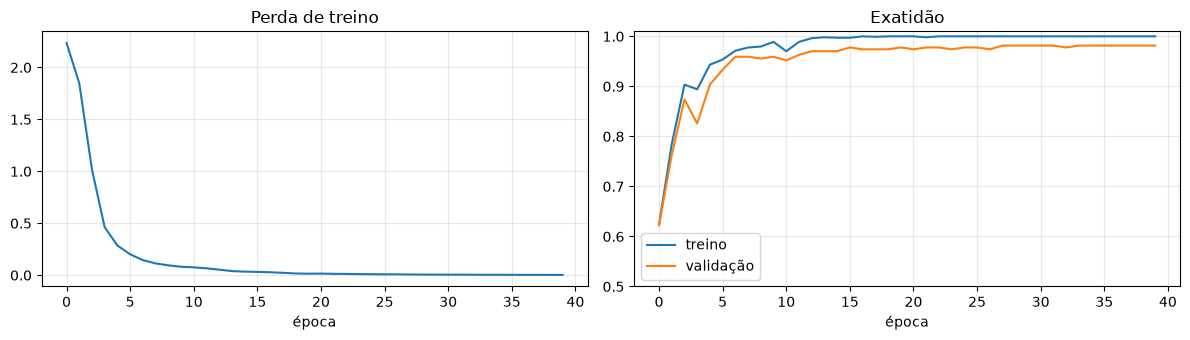

Exatidão: treino 100.0% | validação 98.1%


In [12]:
# Executar esta célula

torch.manual_seed(0)
cnn = CNNDigitos().to(dispositivo)
hist = treinar(cnn)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(hist["perda"])
axs[0].set(title="Perda de treino", xlabel="época")
axs[1].plot(hist["exat_treino"], label="treino")
axs[1].plot(hist["exat_val"], label="validação")
axs[1].set(title="Exatidão", xlabel="época", ylim=(0.5, 1.01))
axs[1].legend()
for ax in axs:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Exatidão: treino {hist['exat_treino'][-1]:.1%} | validação {hist['exat_val'][-1]:.1%}")

## 5. Avaliar

### 5.1 Exatidão no teste e matriz de confusão

Avaliamos uma única vez no teste. Com 10 classes, a **matriz de confusão** mostra que dígitos são confundidos com quais: as linhas são o dígito verdadeiro, as colunas o previsto, e a diagonal os acertos.


Exatidão no teste: 97.8% (10 erros em 450)


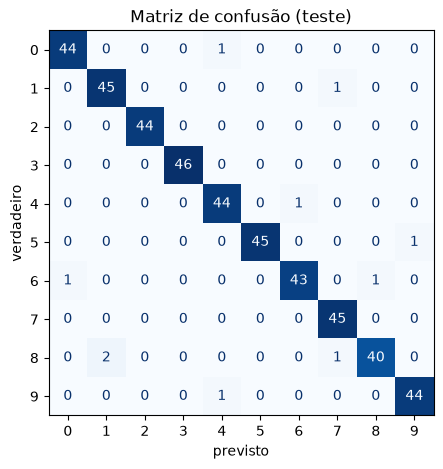

In [13]:
# Executar esta célula

previstos, probabilidades = prever(cnn, X_teste)
print(f"Exatidão no teste: {(previstos == y_teste).mean():.1%} ({(previstos != y_teste).sum()} erros em {len(y_teste)})")

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_teste, previstos)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Matriz de confusão (teste)", xlabel="previsto", ylabel="verdadeiro")
plt.show()

### 5.2 Os erros

Olhar para os exemplos mal classificados é uma das formas mais úteis de perceber um modelo: muitas vezes, os erros são dígitos que uma pessoa também hesitaria em classificar.


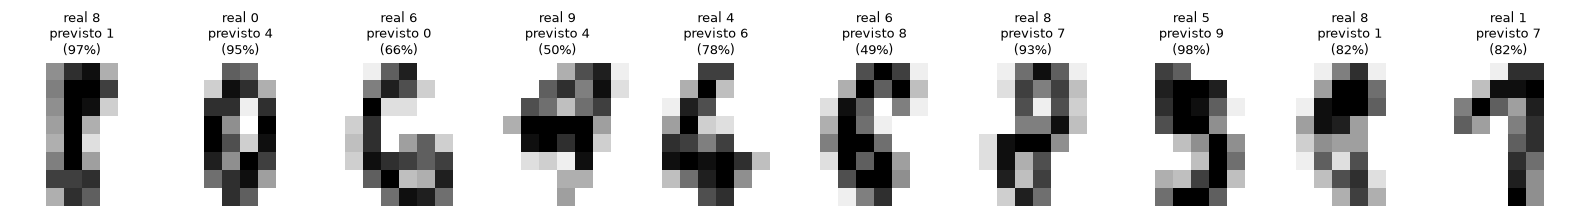

In [14]:
# Executar esta célula

erros = np.flatnonzero(previstos != y_teste)
fig, axs = plt.subplots(1, max(len(erros), 2), figsize=(1.6 * max(len(erros), 2), 2.2))
for ax, i in zip(np.atleast_1d(axs), erros):
    ax.imshow(X_teste[i], cmap="gray_r")
    ax.set_title(f"real {y_teste[i]}\nprevisto {previstos[i]}\n({probabilidades[i].max():.0%})", fontsize=9)
for ax in np.atleast_1d(axs):
    ax.axis("off")
plt.tight_layout()
plt.show()

### 5.3 Probabilidades: quão confiante está a rede?

A *softmax* dá uma probabilidade para cada classe. Num dígito claro, quase toda a probabilidade vai para uma classe; num dígito ambíguo, divide-se por duas ou três. Comparamos o exemplo em que a rede está **mais segura** com o primeiro dos seus erros.


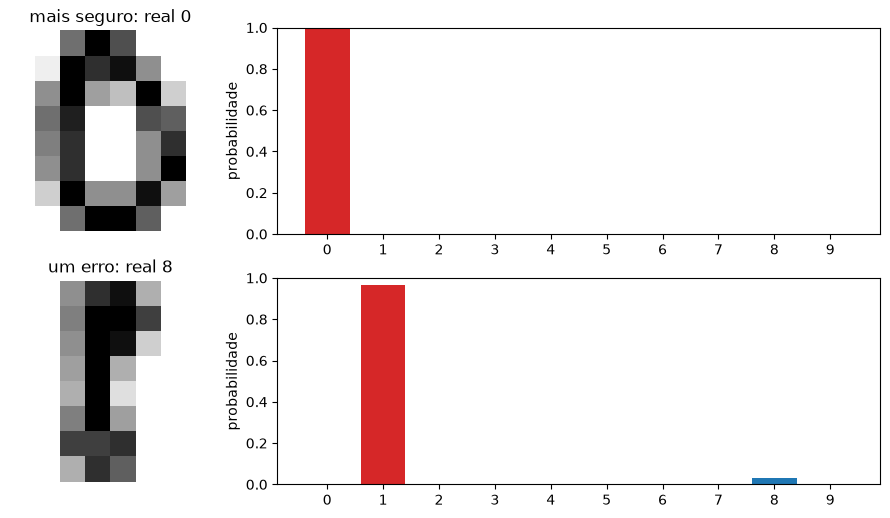

In [15]:
# Executar esta célula

mais_seguro = int(np.argmax(probabilidades.max(axis=1)))
casos = [(mais_seguro, "mais seguro")] + ([(int(erros[0]), "um erro")] if len(erros) else [])
fig, axs = plt.subplots(len(casos), 2, figsize=(9, 2.6 * len(casos)), gridspec_kw={"width_ratios": [1, 3]}, squeeze=False)
for linha, (i, titulo) in enumerate(casos):
    axs[linha, 0].imshow(X_teste[i], cmap="gray_r")
    axs[linha, 0].set_title(f"{titulo}: real {y_teste[i]}")
    axs[linha, 0].axis("off")
    axs[linha, 1].bar(range(10), probabilidades[i], color=["C3" if k == previstos[i] else "C0" for k in range(10)])
    axs[linha, 1].set(xticks=range(10), ylim=(0, 1), ylabel="probabilidade")
plt.tight_layout()
plt.show()

## 6. O que a rede aprendeu

### 6.1 Os filtros da primeira camada

A primeira camada tem 16 filtros de 3 × 3, aprendidos sozinhos durante o treino. Em azul os pesos negativos, em vermelho os positivos. Vários têm um lado positivo e outro negativo, como o filtro de Sobel da secção 2: são **detetores de arestas e traços** em várias direções, que ninguém programou.


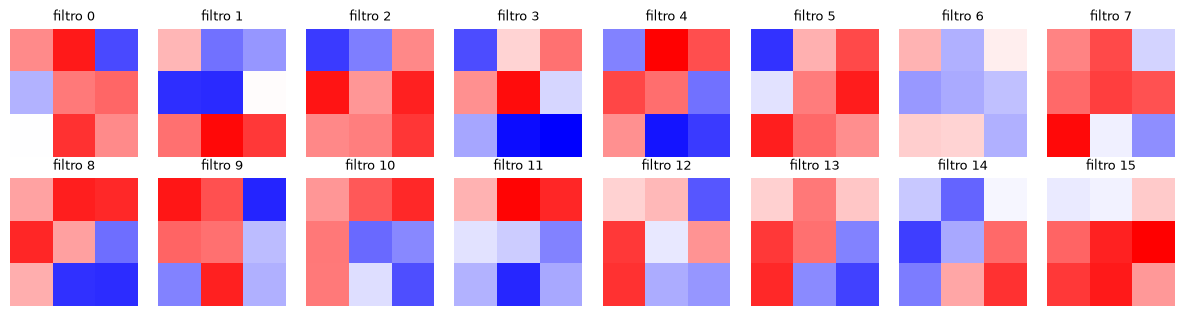

In [16]:
# Executar esta célula

filtros = cnn.extrator[0].weight.detach().cpu().numpy()[:, 0]       # (16, 3, 3)
fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
limite = np.abs(filtros).max()
for k, ax in enumerate(axs.ravel()):
    ax.imshow(filtros[k], cmap="bwr", vmin=-limite, vmax=limite)
    ax.set_title(f"filtro {k}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 6.2 Os mapas de ativação

Para ver o que cada filtro «encontra», passamos um dígito pela primeira convolução e ReLU e mostramos os 16 mapas. Cada um acende-se nas zonas da imagem onde está o padrão do seu filtro.


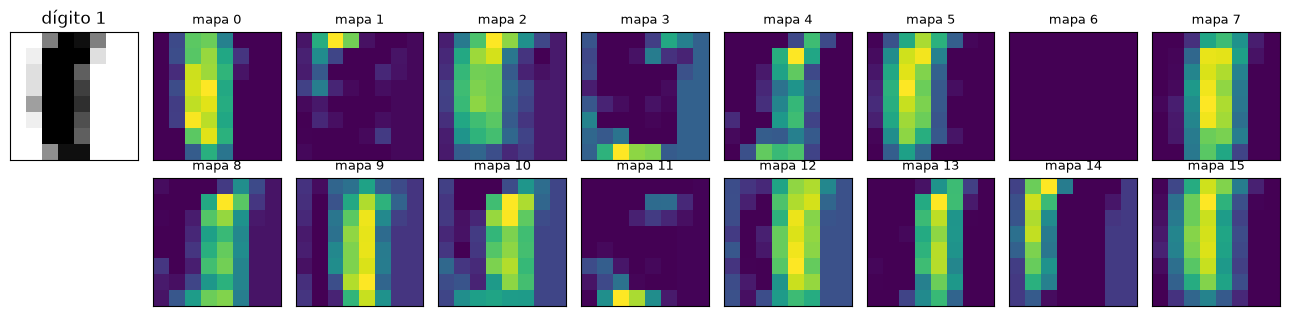

In [17]:
# Executar esta célula

indice = 0
cnn.eval()
with torch.no_grad():
    mapas = cnn.extrator[1](cnn.extrator[0](para_tensor(X_teste[indice:indice + 1]).to(dispositivo)))[0].cpu().numpy()

fig, axs = plt.subplots(2, 9, figsize=(13, 3.2))
axs[0, 0].imshow(X_teste[indice], cmap="gray_r")
axs[0, 0].set_title(f"dígito {y_teste[indice]}")
axs[1, 0].axis("off")
for k in range(16):
    ax = axs.ravel()[k + 1 + (k >= 8)]
    ax.imshow(mapas[k], cmap="viridis")
    ax.set_title(f"mapa {k}", fontsize=9)
for ax in axs.ravel():
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()

## 7. Robustez e *data augmentation*

### 7.1 CNN contra rede densa

Os dígitos 8 × 8 são tão pequenos que uma **rede densa** (como as do N3_04 e N3_05, com a imagem achatada num vetor de 64 valores) também os classifica bem. A diferença vê-se quando as imagens **mudam de posição**: deslocamos os dígitos de teste **um píxel** para cada lado e medimos a exatidão média.

Repara que um píxel, numa imagem de 8, é 12,5 % da largura: é como deslocar uma fotografia 80 píxeis.


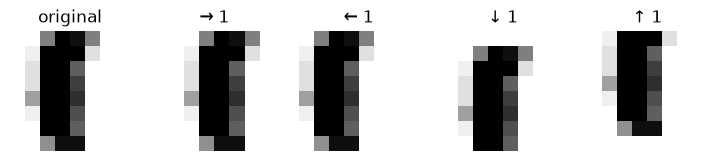

rede densa    4810 parâmetros | teste 96.9% | teste deslocado 1 píxel 42.1%
CNN           6090 parâmetros | teste 97.8% | teste deslocado 1 píxel 62.6%


In [18]:
# Executar esta célula

def rede_densa() -> nn.Module:
    return nn.Sequential(nn.Flatten(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))


def exatidao_deslocada(modelo) -> float:
    """Exatidão média no teste deslocado 1 píxel para a direita, esquerda, baixo e cima."""
    return float(np.mean([exatidao(modelo, deslocar(X_teste, dx, dy), y_teste)
                          for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]]))


fig, axs = plt.subplots(1, 5, figsize=(9, 2))
for ax, (dx, dy, titulo) in zip(axs, [(0, 0, "original"), (1, 0, "→ 1"), (-1, 0, "← 1"), (0, 1, "↓ 1"), (0, -1, "↑ 1")]):
    ax.imshow(deslocar(X_teste[:1], dx, dy)[0], cmap="gray_r")
    ax.set_title(titulo)
    ax.axis("off")
plt.show()

torch.manual_seed(0)
densa = rede_densa().to(dispositivo)
treinar(densa)
resultados = {
    "rede densa": (densa, exatidao(densa, X_teste, y_teste), exatidao_deslocada(densa)),
    "CNN": (cnn, exatidao(cnn, X_teste, y_teste), exatidao_deslocada(cnn)),
}
for nome, (m, normal, deslocado) in resultados.items():
    print(f"{nome:<12} {sum(p.numel() for p in m.parameters()):>5} parâmetros | "
          f"teste {normal:.1%} | teste deslocado 1 píxel {deslocado:.1%}")

No teste normal, as duas são quase iguais. Com as imagens deslocadas, **as duas pioram muito**, mas a CNN aguenta-se bastante melhor: as convoluções reconhecem os traços em qualquer posição e o *pooling* tolera pequenas deslocações. A rede densa, pelo contrário, aprendeu «o píxel (3, 4) costuma estar escuro num 0», e basta mover a imagem para essa regra falhar.

Ainda assim, nenhuma das duas é robusta: nunca viram dígitos deslocados durante o treino.

### 7.2 *Data augmentation*

A solução é **mostrar à rede variações das imagens durante o treino**: em cada época, cada dígito é deslocado ao acaso até um píxel em cada direção. A rede vê assim, de graça, muitas versões diferentes de cada exemplo. Chama-se ***data augmentation*** (aumento de dados) e é usada em praticamente todos os modelos de visão, com rotações, recortes, mudanças de brilho, espelhamentos…

O nosso `Dataset` já tem essa opção (`aumentar=True`): a deslocação é feita no `__getitem__`, por isso é diferente em cada época.


modelo                         teste   deslocado
rede densa                     96.9%       42.1%
CNN                            97.8%       62.6%
rede densa + augmentation      90.2%       87.6%
CNN + augmentation             96.0%       94.3%


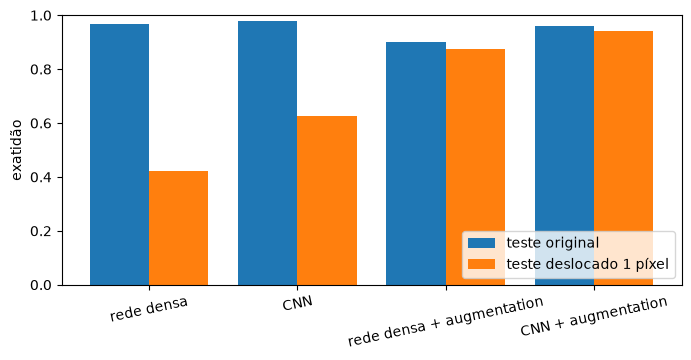

In [19]:
# Executar esta célula

for nome, criar in [("rede densa", rede_densa), ("CNN", CNNDigitos)]:
    torch.manual_seed(0)
    modelo = criar().to(dispositivo)
    treinar(modelo, aumentar=True)
    resultados[f"{nome} + augmentation"] = (modelo, exatidao(modelo, X_teste, y_teste), exatidao_deslocada(modelo))

print(f"{'modelo':<28}{'teste':>8}{'deslocado':>12}")
for nome, (_, normal, deslocado) in resultados.items():
    print(f"{nome:<28}{normal:>8.1%}{deslocado:>12.1%}")

nomes = list(resultados)
posicoes = np.arange(len(nomes))
plt.figure(figsize=(8, 3.5))
plt.bar(posicoes - 0.2, [resultados[n][1] for n in nomes], 0.4, label="teste original")
plt.bar(posicoes + 0.2, [resultados[n][2] for n in nomes], 0.4, label="teste deslocado 1 píxel")
plt.xticks(posicoes, nomes, rotation=12)
plt.ylabel("exatidão")
plt.legend(loc="lower right")
plt.ylim(0, 1)
plt.show()

Com *data augmentation*, a exatidão da CNN nas imagens deslocadas fica muito perto da das originais, à custa de perder um pouco nestas (a tarefa de treino ficou mais difícil). A rede densa também melhora muito nas deslocadas, mas paga um preço maior: perde vários pontos nas imagens originais, porque tem de «decorar» cada posição possível separadamente. A combinação **CNN + *data augmentation*** é a que generaliza melhor, e é o ponto de partida habitual em visão computacional.

> Com o `torchvision`, as transformações para *data augmentation* já vêm feitas: por exemplo, `transforms.RandomAffine(degrees=10, translate=(0.1, 0.1))` aplica rotações e deslocações aleatórias.


## 8. Opcional: Fashion-MNIST

O **Fashion-MNIST** tem 70 000 imagens de 28 × 28 píxeis de dez tipos de roupa e calçado (t-shirts, calças, sapatilhas, malas…). É mais difícil do que os dígitos e mais parecido com um problema real. Precisa de **Internet** para descarregar os dados (cerca de 30 MB) e da biblioteca `torchvision`, que já vem no Colab. Se não estiverem disponíveis, as células seguintes avisam e não fazem nada.

Recomenda-se usar a **GPU** do Colab: com CPU, cada época demora um ou dois minutos.


In [20]:
# Executar esta célula

CLASSES_FASHION = ["t-shirt", "calças", "camisola", "vestido", "casaco",
                   "sandália", "camisa", "sapatilha", "mala", "bota"]
try:
    from torchvision import datasets, transforms
    fashion_treino = datasets.FashionMNIST("dados_fashion", train=True, download=True, transform=transforms.ToTensor())
    fashion_teste = datasets.FashionMNIST("dados_fashion", train=False, download=True, transform=transforms.ToTensor())
    fashion_disponivel = True
    print(f"Fashion-MNIST: {len(fashion_treino)} imagens de treino, {len(fashion_teste)} de teste.")
except Exception as erro:                              # sem Internet ou sem torchvision
    fashion_disponivel = False
    print(f"Fashion-MNIST não disponível ({type(erro).__name__}). Esta secção é opcional: podes continuar.")

Fashion-MNIST não disponível (RuntimeError). Esta secção é opcional: podes continuar.


In [21]:
# Executar esta célula

class CNNFashion(nn.Module):
    """Duas convoluções para imagens 28×28: 28 → 14 → 7."""

    def __init__(self):
        super().__init__()
        self.extrator = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classificador = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
                                           nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classificador(self.extrator(x))


if fashion_disponivel:
    torch.manual_seed(0)
    modelo_fashion = CNNFashion().to(dispositivo)
    carregador = DataLoader(fashion_treino, batch_size=128, shuffle=True)
    otimizador = torch.optim.Adam(modelo_fashion.parameters(), lr=1e-3)
    for epoca in range(3):                                # 3 épocas: ~90 % de exatidão
        perda = treinar_epoca(modelo_fashion, carregador, nn.CrossEntropyLoss(), otimizador)
        print(f"época {epoca + 1}: perda {perda:.3f}")

    modelo_fashion.eval()
    certos, previstos_f = 0, []
    with torch.no_grad():
        for X_lote, y_lote in DataLoader(fashion_teste, batch_size=1000):
            p = modelo_fashion(X_lote.to(dispositivo)).argmax(dim=1).cpu()
            certos += (p == y_lote).sum().item()
            previstos_f.append(p)
    print(f"Exatidão no teste: {certos / len(fashion_teste):.1%}")

    previstos_f = torch.cat(previstos_f).numpy()
    fig, axs = plt.subplots(2, 8, figsize=(13, 3.8))
    for ax, i in zip(axs.ravel(), range(16)):
        imagem, real = fashion_teste[i]
        ax.imshow(imagem[0], cmap="gray_r")
        cor = "green" if previstos_f[i] == real else "red"
        ax.set_title(f"{CLASSES_FASHION[previstos_f[i]]}\n(real: {CLASSES_FASHION[real]})", fontsize=8, color=cor)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Experimenta

### Exercício 1 – Quantos filtros?

Treina a `CNNDigitos` com 4 e 8 filtros na primeira camada (e o dobro na segunda), e compara o número de parâmetros e a exatidão no teste e no teste deslocado com a rede de 16 + 32 filtros.


In [22]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for f1 in [4, 8, 16]:
    torch.manual_seed(0)
    m = CNNDigitos(filtros1=f1, filtros2=2 * f1).to(dispositivo)
    treinar(m)
    print(f"{f1:>2} + {2 * f1:<2} filtros | {sum(p.numel() for p in m.parameters()):>5} parâmetros | "
          f"teste {exatidao(m, X_teste, y_teste):.1%} | deslocado {exatidao_deslocada(m):.1%}")
# Mesmo com 4 + 8 filtros (menos de 700 parâmetros) a CNN chega a valores altos:
# os dígitos 8×8 são um problema pequeno. Mais filtros ajudam pouco aqui, mas são
# essenciais em imagens maiores e mais variadas.
```

</details>


### Exercício 2 – Rotações

Acrescenta ao *data augmentation* pequenas rotações aleatórias (entre −15° e 15°), usando `scipy.ndimage.rotate(img, angulo, reshape=False)`. Cria um teste com os dígitos rodados 15° e compara a CNN treinada só com deslocações com a CNN treinada com deslocações e rotações.


In [23]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from scipy.ndimage import rotate


class DigitosRodados(Digitos):
    def __getitem__(self, i):
        img, rotulo = super().__getitem__(i)                 # já deslocada, se aumentar=True
        angulo = np.random.uniform(-15, 15)
        img = rotate(img[0].numpy(), angulo, reshape=False, order=1)
        return torch.tensor(img, dtype=torch.float32).unsqueeze(0), rotulo


teste_rodado = np.stack([rotate(im, 15, reshape=False, order=1) for im in X_teste]).astype(np.float32)

np.random.seed(0)
torch.manual_seed(0)
cnn_rot = CNNDigitos().to(dispositivo)
carregador = DataLoader(DigitosRodados(X_treino, y_treino, aumentar=True), batch_size=64, shuffle=True,
                        generator=torch.Generator().manual_seed(0))
otimizador = torch.optim.Adam(cnn_rot.parameters(), lr=3e-3)
for _ in range(40):
    treinar_epoca(cnn_rot, carregador, nn.CrossEntropyLoss(), otimizador)

so_deslocacoes = resultados["CNN + augmentation"][0]
for nome, m in [("só deslocações", so_deslocacoes), ("deslocações + rotações", cnn_rot)]:
    print(f"{nome:<24} teste {exatidao(m, X_teste, y_teste):.1%} | "
          f"rodado 15° {exatidao(m, teste_rodado, y_teste):.1%}")
# As rotações tornam a rede muito mais robusta a dígitos rodados, mas, com só
# ~1000 exemplos e 40 épocas, perde alguma exatidão no teste original: quanto
# mais variação se acrescenta, mais treino (e dados) a rede precisa.
```

</details>


### Exercício 3 – Desenha um dígito

Desenha um dígito numa matriz 8 × 8, com valores de 0 (branco) a 16 (preto), como as do conjunto de dados. Mostra-o, e usa a CNN treinada com *data augmentation* para o classificar, com o gráfico das probabilidades das 10 classes.


In [24]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
meu_digito = np.array([
    [0,  0, 12, 16, 16, 14,  0, 0],
    [0,  0,  0,  0,  0, 16,  2, 0],
    [0,  0,  0,  0,  4, 14,  0, 0],
    [0,  0,  0,  0, 12,  8,  0, 0],
    [0,  0,  0,  4, 14,  0,  0, 0],
    [0,  0,  0, 12,  8,  0,  0, 0],
    [0,  0,  2, 16,  2,  0,  0, 0],
    [0,  0,  6, 12,  0,  0,  0, 0],
], dtype=np.float32) / 16                                   # um 7

modelo = resultados["CNN + augmentation"][0]
classe, prob = prever(modelo, meu_digito[None])
fig, axs = plt.subplots(1, 2, figsize=(8, 2.6), gridspec_kw={"width_ratios": [1, 3]})
axs[0].imshow(meu_digito, cmap="gray_r")
axs[0].set_title(f"previsto: {classe[0]}")
axs[0].axis("off")
axs[1].bar(range(10), prob[0])
axs[1].set(xticks=range(10), ylim=(0, 1), ylabel="probabilidade")
plt.tight_layout()
plt.show()
```

</details>


## Verifica o que aprendeste

1. O que significam as quatro dimensões de um tensor de imagens (N, C, A, L)? Que forma tem um lote de 64 dígitos 8 × 8?
2. O que faz uma convolução, e o que muda quando se aumenta o `padding` ou o `stride`?
3. Uma imagem 8 × 8 passa por `Conv2d(1, 16, kernel_size=3, padding=1)` e depois por `MaxPool2d(2)`. Que forma tem a saída?
4. Quais são as duas grandes vantagens das convoluções em relação às camadas densas, em imagens?
5. Para que serve o *max pooling*?
6. Com 10 classes, quantas saídas tem a rede, e o que fazem a *softmax* e a `nn.CrossEntropyLoss`? Que tipo devem ter os rótulos?
7. Porque é que a rede densa piorou tanto nas imagens deslocadas, e porque é que a CNN piorou menos?
8. O que é *data augmentation*, e porque se aplica no `__getitem__` do `Dataset`?

<details>
<summary><b>Ver respostas</b></summary>

1. Número de imagens, canais, altura e largura. Um lote de 64 dígitos tem forma (64, 1, 8, 8).
2. Passa um filtro pela imagem e, em cada posição, soma os produtos dos pesos pelos píxeis. O `padding` acrescenta zeros à volta (a saída encolhe menos ou mantém o tamanho); o `stride` faz o filtro saltar píxeis (a saída fica mais pequena).
3. A convolução mantém 8 × 8 (com 16 canais): (N, 16, 8, 8); o *pooling* reduz para (N, 16, 4, 4).
4. Partilham os pesos por todas as posições (muito menos parâmetros) e reconhecem um padrão em qualquer sítio da imagem.
5. Reduz o tamanho dos mapas (menos cálculo e parâmetros) e torna a rede tolerante a pequenas deslocações.
6. Dez saídas (*logits*), uma por classe. A *softmax* transforma-os em probabilidades que somam 1; a `CrossEntropyLoss` aplica a *softmax* e calcula a perda. Os rótulos são inteiros (`torch.long`) de 0 a 9.
7. A rede densa aprende regras ligadas a píxeis em posições fixas, que falham quando a imagem se move. A CNN reconhece os traços em qualquer posição e o *pooling* tolera deslocações pequenas.
8. É mostrar à rede variações aleatórias das imagens de treino (deslocações, rotações…). No `__getitem__`, a variação é sorteada de novo cada vez que a imagem é pedida, ou seja, em cada época.

</details>

## Leitura recomendada

- LeCun, Y., Bottou, L., Bengio, Y. e Haffner, P. (1998). «[Gradient-based learning applied to document recognition](https://doi.org/10.1109/5.726791)». *Proceedings of the IEEE*, 86(11), 2278–2324. O artigo da LeNet, a CNN que reconhecia dígitos em cheques bancários.
- [CS231n: *Convolutional Neural Networks for Visual Recognition*](https://cs231n.github.io/convolutional-networks/). Universidade de Stanford. As notas do curso explicam convoluções, *pooling* e arquiteturas com muito cuidado.
- Dumoulin, V. e Visin, F. (2016). «[A guide to convolution arithmetic for deep learning](https://arxiv.org/abs/1603.07285)». As fórmulas de *padding* e *stride*, com animações.
- Goodfellow, I., Bengio, Y. e Courville, A. (2016). *[Deep Learning](https://www.deeplearningbook.org/)*. MIT Press. Capítulo 9.
- Zhang, A., Lipton, Z. C., Li, M. e Smola, A. J. (2023). *[Dive into Deep Learning](https://d2l.ai/)*. Cambridge University Press. Capítulos 7 e 8.
- Xiao, H., Rasul, K. e Vollgraf, R. (2017). «[Fashion-MNIST: a novel image dataset for benchmarking machine learning algorithms](https://arxiv.org/abs/1708.07747)».
- [Tutorial do PyTorch: *Training a Classifier*](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html). Uma CNN para imagens a cores (CIFAR-10).
- **Módulos relacionados:** N3_04 (redes neuronais de raiz) e N3_05 (PyTorch).
